# Convolutional Neural Network

A Convolutional Neural Network is a deep learning model designed specifically for processing grid-like data, such as images or videos.

While traditional neural networks treat images as flat lists of individual pixels, CNNs preserve the spatial structure making them exceptionally effective at understanding patterns in visual data.

# Where are they used mainly

- Image Classification

- Object Detection & Localization

- Medical Imaging

- Facial Recognition

# How CNN is made

A CNN is built stacking 4 different layers in a pipeline 

Input -> Convolution Layer -> Relu Activation -> Pooling Layer -> Fully connected Layer -> Output Class

In particular:

*Convolutional Layer* uses small matrices called filters or kernels (e.g., $3 \times 3$ or $5 \times 5$ grids of numbers) that slide across the input image to detect features like edges, corners, and color gradients.

*ReLU (Rectified Linear Unit) Activation Layer* introduces non-linearity into the network using a simple rule:

$$f(x) = \max(0, x)$$

It turns all negative pixel values to $0$ while keeping positive values unchanged. 

This allows the network to learn complex, real-world patterns rather than just simple linear mappings.

*Pooling Layer*  reduces the spatial dimensions (width and height) of the feature maps, which speeds up processing and reduces memory usage, by sliding a window (e.g., $2 \times 2$) across the image and keeps only the maximum value in each window.

*Fully Connected (FC) Layer* Located at the end of the CNN, this layer flattens the multidimensional feature maps into a 1D vector and connects every neuron to the output nodes to produce the final classification probabilities

# How Does it works

*1 Feature Extraction via Sliding Filters*

The filter slides across the input image pixel by pixel (a step size called stride). At each position, it calculates an element-wise multiplication with the image section beneath it and sums the result to create a single number in a new matrix known as a Feature Map.

*2 Non-Linear Activation*

The feature map passes through the ReLU function. All negative numerical values are replaced with zero, highlighting only the activated positive features and removing unnecessary negative signals.

*3 Dimensionality Reduction*

The feature map is downsampled using Max Pooling, retaining only the strongest features from each local region. This step also grants the network translation invariance, meaning it can detect an object regardless of where it appears in the frame.

*4 Hierarchical Feature Learning*

Steps 1 to 3 are repeated across multiple deep layers.

*5 Final Classification*

The complex high-level features are flattened into a 1D vector and passed through a Fully Connected Layer. A Softmax activation function converts the raw output numbers into probability scores for each class category.


# Libraries

TensorFlow provides the tools needed to load the CIFAR-10 dataset and build the Convolutional Neural Network. NumPy is used to perform numerical operations on the data, while Matplotlib allows images and charts to be displayed.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Loading the CIFAR-10 Dataset

The CIFAR-10 dataset is a commonly used dataset for image classification tasks. It contains 60,000 colour images divided into ten different classes, including aeroplanes, cars, birds, cats and dogs. Each image has a resolution of 32 × 32 pixels and contains three colour channels: red, green and blue (RGB).

TensorFlow provides a built-in function to load this dataset. The function returns two groups of data: a training dataset and a test dataset.

In [2]:
# Load the CIFAR-10 dataset
dataset = tf.keras.datasets.cifar10.load_data()

# Split the dataset into training and test sets
(x_train, y_train), (x_test, y_test) = dataset

The variables x_train and x_test contain the images used for training and testing the model, respectively. The variables y_train and y_test contain the corresponding labels, which identify the class associated with each image.

Separating the dataset into training and test sets is important because the model needs to learn patterns from one group of images and then be evaluated on images that were not used during training. This helps assess whether the model can generalise its predictions to previously unseen data.


# Checking the Number of Images

The training dataset contains 50,000 images, while the test dataset contains 10,000 images. This means that approximately 83.3% of the images are allocated to training and 16.7% to testing.

Checking the number of records is a basic data validation step. It confirms that the dataset has been loaded correctly and provides an initial understanding of the amount of data available to train and evaluate the CNN.

In [3]:
print("Number of training images:", len(x_train))
print("Number of training labels:", len(y_train))

print("Number of test images:", len(x_test))
print("Number of test labels:", len(y_test))

Number of training images: 50000
Number of training labels: 50000
Number of test images: 10000
Number of test labels: 10000


# Understanding the Shape of the Data

These dimensions indicate the number of images, image height, image width and number of colour channels, in that order.

For example, the shape (50000, 32, 32, 3) means that the training set contains 50,000 images, each consisting of 32 pixels in height, 32 pixels in width and three RGB colour channels.

The label arrays have shapes (50000, 1) and (10000, 1). Each image has one corresponding class label. Understanding these dimensions is important because the input shape must be compatible with the architecture of the CNN.

In [4]:
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

print("Test images shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test images shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)


# Defining the Class Names

The CIFAR-10 labels are represented by integer values from 0 to 9 rather than by descriptive class names. To make the labels easier to interpret, a list containing the ten class names can be created.

In [5]:
class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

In [6]:
print("First image label:", y_train[0, 0])
print("First image class:", class_names[int(y_train[0, 0])])

First image label: 6
First image class: Frog


The position of each class in the list corresponds to its numerical label. For example, label 0 represents an aeroplane, while label 3 represents a cat.

This mapping is useful when exploring the dataset and interpreting the model's predictions. Instead of displaying a numerical value, the code can show the corresponding class name, making the results easier to understand.

# Inspecting an Individual Image

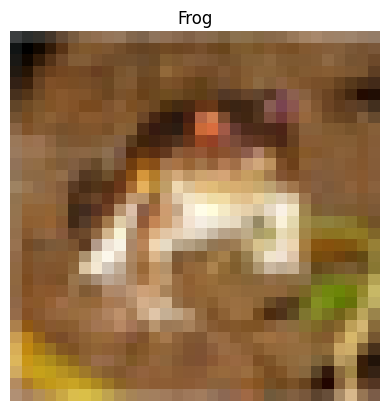

In [7]:
# Select the first image
image = x_train[0]

# Get the correct label
label = int(y_train[0, 0])

# Display the image
plt.imshow(image)
plt.title(class_names[label])
plt.axis("off")
plt.show()

The expression x_train[0] selects the first image in the training dataset. Similarly, y_train[0][0] retrieves the numerical label associated with that image. The class name is obtained by using this label as an index in the class_names list.

The function plt.imshow() displays the image, while plt.title() adds the corresponding class name above it. The command plt.axis("off") removes the axis markings because they are not necessary for this visual inspection.

This step allows the image and its label to be checked together. It provides a simple way to confirm that the images can be displayed correctly and that their labels can be interpreted.

# Visualising Multiple Images

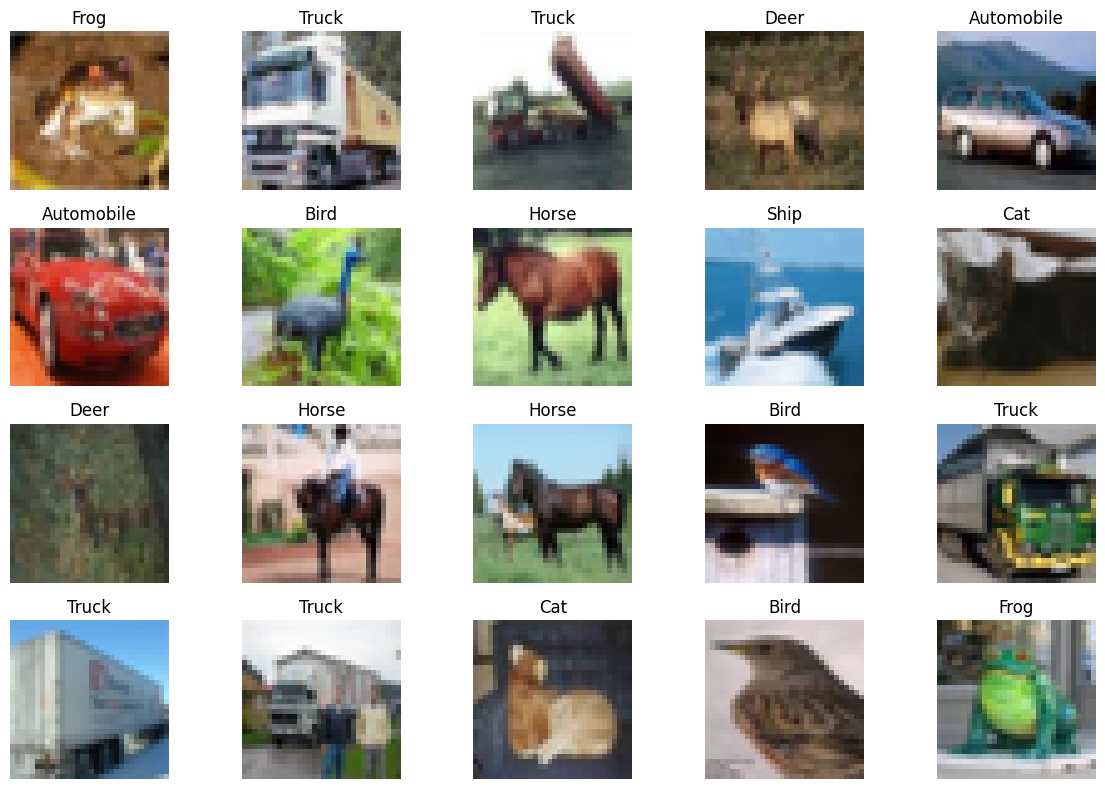

In [8]:
plt.figure(figsize=(12, 8))

for i in range(20):

    plt.subplot(4, 5, i + 1)

    plt.imshow(x_train[i])

    label = int(y_train[i, 0])

    plt.title(class_names[label])

    plt.axis("off")

plt.tight_layout()
plt.show()

The function plt.figure() defines the overall size of the visualisation. The loop then selects the first 20 images from the training dataset. For each iteration, plt.subplot(4, 5, i + 1) creates a position within a grid containing four rows and five columns.

The selected image is displayed in its position, and its corresponding class name is used as the title. The i + 1 expression is required because Matplotlib numbers subplot positions starting from 1, whereas Python indexes arrays starting from 0.

Finally, plt.tight_layout() adjusts the spacing between the images to reduce overlap between titles and neighbouring plots.

This visualisation helps identify the characteristics of the dataset before model development. For example, images belonging to the same class may have different backgrounds, viewing angles or object sizes. These variations make image classification more challenging and explain why a CNN needs to learn useful visual features rather than simply memorising individual images.

# Examining the Pixel Values

Each pixel in a colour image contains three values corresponding to its red, green and blue channels. In the original CIFAR-10 dataset, these pixel values are stored as unsigned 8-bit integers (uint8) and range from 0 to 255.

In [9]:
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Data type:", x_train.dtype)

Minimum pixel value: 0
Maximum pixel value: 255
Data type: uint8


The data type indicates how the pixel values are stored, while the minimum and maximum functions show the range of values present in the training images.

A value of 0 represents the minimum intensity for a colour channel, whereas 255 represents the maximum intensity. Different combinations of these values produce the colours visible in the images.

Examining the pixel values is important because the data must be prepared appropriately before it is passed to the neural network. In particular, the original values have a relatively large numerical range compared with the normalised values commonly used when training neural networks.

# Analysing the Distribution of Classes

A dataset in which some classes contain significantly more examples than others may introduce class imbalance, potentially affecting the model's ability to recognise less-represented categories.

The following code counts the number of training images associated with each class.

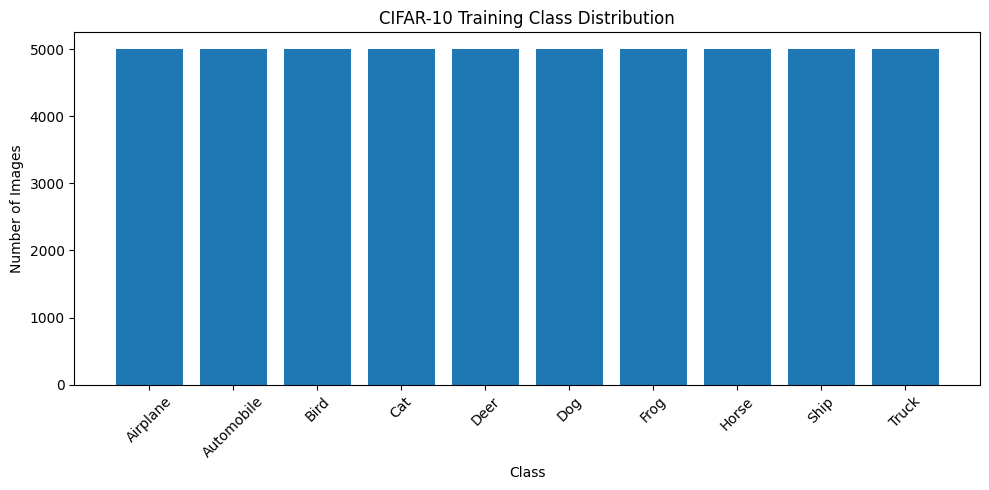

In [10]:
# Count the images belonging to each class
class_counts = np.bincount(y_train.flatten())

# Display the class distribution
plt.figure(figsize=(10, 5))

plt.bar(class_names, class_counts)

plt.title("CIFAR-10 Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The function y_train.flatten() converts the label array from a two-dimensional structure into a one-dimensional array. This is useful because np.bincount() counts the occurrences of each non-negative integer label.

The resulting counts are displayed in a bar chart. Each bar represents one class, and its height indicates the number of training images belonging to that category.

CIFAR-10 is balanced across its ten classes, with 5,000 training images per class. This means that each category has the same number of training examples, reducing concerns about class imbalance in the original training dataset.

Although a balanced dataset does not guarantee good classification performance, it provides a useful starting point because the model is not exposed to one class substantially more often than another during training.

# Normalising the Images

In [11]:
# Convert pixel values to float and normalise them
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Data type:", x_train.dtype)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: float32


The method astype("float32") converts the pixel values from unsigned integers to floating-point numbers. Dividing by 255 then rescales the original range of 0–255 to the range 0–1.

For example, an original pixel value of 255 becomes 1.0, while a value of 128 becomes approximately 0.502. This transformation preserves the relative intensity of the pixels while reducing the numerical scale of the input data.

Normalisation is a common preprocessing technique in neural networks because it can help make optimisation more stable and improve the efficiency of training. It is applied consistently to both training and test images so that the model receives data in the same format during learning and evaluation.

The labels do not need to be normalised because they represent discrete class identifiers rather than continuous input features.

# Building the CNN architecture

A CNN is designed to identify visual patterns in images. Instead of treating every pixel as an independent feature from the beginning, it uses convolutional layers to learn local patterns such as edges, textures and shapes.

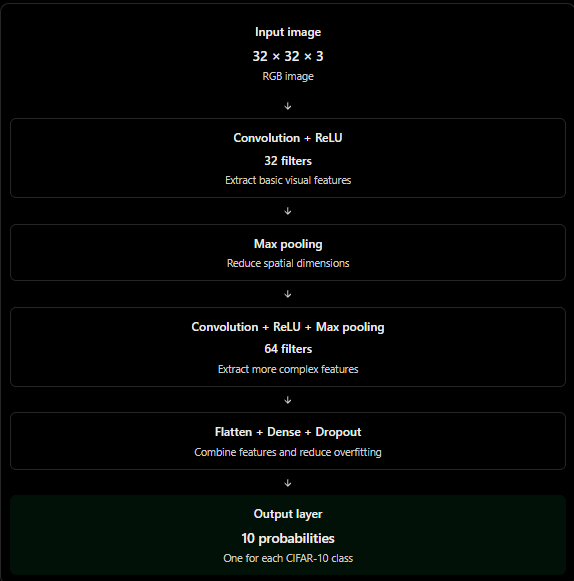

In [3]:
# Import the required layers
from tensorflow.keras import layers, models

# Create the CNN model
model = models.Sequential([

    # First convolutional block
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(32, 32, 3)
    ),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Learn from the extracted features
    layers.Dense(64, activation="relu"),

    # Reduce overfitting
    layers.Dropout(0.3),

    # Output probabilities for the 10 classes
    layers.Dense(10, activation="softmax")
])

C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Convolutional layers

The first Conv2D layer contains 32 filters, each with a size of 3 × 3 pixels. These filters move across the image and learn to identify local patterns, such as edges, colour transitions and simple textures. 

The filters are not manually defined; their values are learned during training through the optimisation process.

The parameter input_shape=(32, 32, 3) specifies the dimensions of each input image. 

The first two dimensions represent the image height and width, while the third represents the three RGB colour channels. This matches the structure of the CIFAR-10 images.

The second convolutional layer contains 64 filters increasing the number of filters allows the network to learn a wider range of features. 

While the first layer may learn relatively simple patterns, later layers can combine information from earlier layers to recognise more complex structures.

Both convolutional layers use the ReLU activation function. ReLU returns zero for negative input values and leaves positive values unchanged. 

This introduces non-linearity, allowing the network to learn more complex relationships than a model composed only of linear operations.

### Max pooling layers

Each convolutional block is followed by a MaxPooling2D((2, 2)) layer. Max pooling divides the feature maps into small 2 × 2 regions and retains the maximum value from each region.

This operation reduces the spatial dimensions of the feature maps, making subsequent computations more efficient. It also helps the network focus on the strongest detected features rather than retaining every spatial detail.

In this architecture, the convolutional layers use Keras' default padding="valid", meaning no additional border pixels are added.

### Flatten and Dense layers

The Flatten() layer converts the three-dimensional feature maps into a one-dimensional vector. After the second pooling layer, the representation has dimensions of 6 × 6 × 64, giving 2,304 values. 

Flattening allows these values to be passed into a fully connected neural network.

The Dense(64, activation="relu") layer learns relationships between the extracted features. For example, combinations of edges, textures and shapes may provide evidence that an image contains a cat rather than a dog.

The Dropout(0.3) layer randomly disables 30% of the units in the preceding layer during training. This acts as a regularisation technique by discouraging the network from relying too heavily on particular neurons. 

It can help reduce overfitting, although its effectiveness must be assessed using validation results.

### Output layer

The final layer contains ten units because CIFAR-10 has ten possible classes. Each unit produces a score converted into a probability by the softmax activation function.

The resulting probabilities sum to approximately 1 for each image. The class with the highest probability becomes the model's predicted class. 

For example, if the highest probability corresponds to the Cat class, the model predicts that the image contains a cat.

# Inspecting the model

In [4]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

The summary() method displays each layer, its output shape and its number of parameters. 

Trainable parameters are the values adjusted during training to improve the model's predictions. Examining them helps us understand the model's complexity and identify the main components of the network.

# Compiling the CNN

Before training, the CNN must be compiled with an optimiser, a loss function and evaluation metrics.

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

The Adam optimiser updates the model's trainable parameters to reduce the loss. It adapts the size of the updates during training and is commonly used as a starting point for neural network experiments.

The sparse_categorical_crossentropy loss function is appropriate because this is a multi-class classification problem and the labels are stored as integer class identifiers from 0 to 9. 

It measures how well the predicted probability distribution matches the correct class. Using this loss avoids the need to convert the labels into one-hot encoded vectors.

Accuracy is included as an evaluation metric. 

It measures the proportion of images for which the predicted class matches the true label. However, accuracy alone does not explain which classes are difficult to recognise, so further evaluation will be required after training.

# Training the CNN

In [6]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    shuffle=True
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.1342 - loss: 2.6488 - val_accuracy: 0.1999 - val_loss: 2.1242
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.2102 - loss: 2.0291 - val_accuracy: 0.2871 - val_loss: 1.8568
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.2833 - loss: 1.8599 - val_accuracy: 0.3581 - val_loss: 1.6818
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.3320 - loss: 1.7406 - val_accuracy: 0.4377 - val_loss: 1.5133
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.3801 - loss: 1.6553 - val_accuracy: 0.4963 - val_loss: 1.4655
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.4062 - loss: 1.5810 - val_accuracy: 0.5145 - val_loss: 1.3973
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.4305 - loss: 1.5368 - val_accuracy: 0.5379 - val_loss: 1.3499
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.4486 - loss: 1.4975 - val_

During training, the model processes batches of images, generates predictions, calculates the loss and updates its parameters using the optimiser. 

One epoch represents one complete pass through the training data, although the model processes the data in smaller batches.

The batch_size=64 setting means that the model processes 64 images at a time before performing an optimiser update. The epochs=10 setting specifies ten passes through the training portion of the data.

The validation_split=0.2 setting reserves 20% of the supplied training data for validation. Consequently, 40,000 images are used for parameter updates and 10,000 are used to monitor performance during training. The separate 10,000-image test set remains untouched for the final evaluation.

The shuffle=True setting randomises the order of the training examples between epochs. This is generally suitable for an image-classification dataset such as CIFAR-10.

The training results are stored in history. This object contains the loss and accuracy recorded across the epochs, including the corresponding validation metrics. These values can be used to plot learning curves and assess whether the model is improving or showing signs of overfitting.

### Results

Over the course of training, the model's performance improved significantly—climbing from an accuracy of 13.4% to 49.2% on the training set, while the validation accuracy rose even higher, from 20.0% to 56.5%. Simultaneously, validation loss decreased steadily from 2.12 down to 1.25.

Throughout this phase, validation metrics consistently outperformed training performance, confirming that the network's Dropout layer is effectively preventing overfitting and encouraging strong feature generalization. Operating at roughly 15ms per step (~10 seconds per epoch across 625 batches), the pipeline maintained excellent computational efficiency. Because both loss curves are still on a downward trajectory without signs of plateauing, extending training or introducing learning rate scheduling in subsequent runs will likely unlock further performance gains.

# Evaluating the model on the test set

In [7]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print("Test accuracy (%):", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5707 - loss: 1.2389
Test loss: 1.2388581037521362
Test accuracy: 0.5706999897956848
Test accuracy (%): 57.06999897956848


Evaluating the model on the unseen test set yields a final accuracy of 57.07% alongside a test loss of 1.24. 

Because these metrics mirror the final validation results closely, they confirm that the network generalizes effectively to completely new data without showing signs of overfitting. 

Achieving over 57% accuracy on a 10-class classification task after only 10 epochs establishes a robust baseline demonstrating that the architecture has learned meaningful features and holds strong potential for further optimization in subsequent training iterations.

# Visualising the learning curves

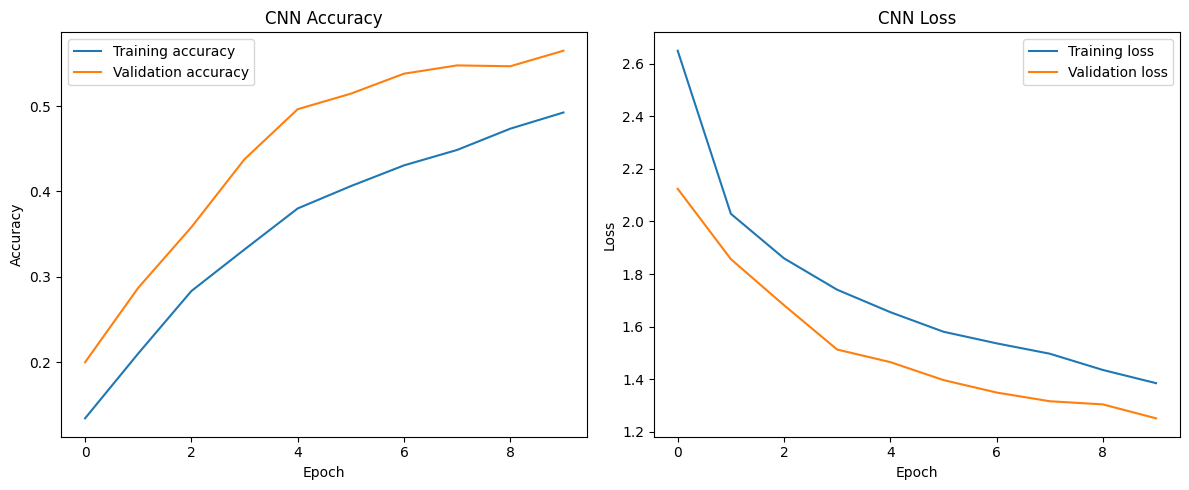

In [8]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.show()

The accuracy plot shows whether the model becomes more accurate as training progresses. The loss plot shows whether the prediction error decreases. Comparing the training and validation curves is particularly important.

If training accuracy continues to increase while validation accuracy stops improving or decreases, and the validation loss begins to increase, this may indicate overfitting. 

On the other hand, if both training and validation performance remain poor, the model may be underfitting, or its architecture and training settings may need further investigation.

These plots provide evidence for decisions about the number of epochs, the architecture and regularisation. They are more informative than relying on a single final accuracy value.

# Conclusion

This project demonstrated the development of a Convolutional Neural Network (CNN) using TensorFlow and Keras to perform image classification on the CIFAR-10 dataset. The process started with dataset loading, exploration and preprocessing, including visualising the images, examining the class distribution and normalising pixel values.

The CNN architecture was then developed using convolutional layers to extract visual features, max-pooling layers to reduce spatial dimensions, and dense layers to classify the extracted information. The model was compiled using the Adam optimiser, sparse categorical cross-entropy as the loss function, and accuracy as an evaluation metric.

The training and validation results, together with the final test evaluation, provide a basis for assessing the model's ability to classify unseen images. The learning curves can also help identify potential overfitting and determine whether further improvements are required.

Overall, this project provided practical experience in developing a deep learning model and understanding the main stages of an image classification workflow. Further improvements could include data augmentation, hyperparameter tuning and a confusion matrix to investigate classification errors across the ten classes. These experiments would help establish whether the model's performance can be improved and provide a more comprehensive evaluation of its strengths and limitations.